# Face classification optimization
Thuận Minh · Hawkeye · ResNet-18 · 512-dimensional embeddings

This notebook contains the complete implementation for data preparation, integrity checks, cached RGB data, the model, training, checkpoint recovery, validation-based selection, final evaluation and plots. Run the cells from top to bottom on the local RTX 4060 or a Google Colab GPU.

The recorded baseline reached 62.325% validation accuracy and 62.328% test accuracy with substantial overfitting. The new study compares 96×96 and 128×128 inputs using the same regularized fine-tuning recipe and initialization. Candidate selection uses validation. The selected candidate receives further training before final test evaluation.

The existing dataset, cache and baseline checkpoint are experiment inputs. Python dependencies are standard scientific packages. Every project-specific function is defined in the cells below.

## Colab trial

1. Upload this notebook through **File > Upload notebook** in Colab.
2. Select a GPU through **Runtime > Change runtime type**. This trial does not require a paid upgrade.
3. Run all cells. The default Colab mode is **benchmark**, which runs one full 128 x 128 training epoch and does not launch the 26-epoch study or evaluate the test set.
4. When requested, upload **colab_transfer_v1.zip** (about 121 MB). It contains the audited manifest, existing model weights and measured reports. The public Kaggle archive downloads directly to the Colab VM.
5. Google Drive mounting requests your authorization. Checkpoints and benchmark reports are copied to **MyDrive/Hawkeye/face_recognition/colab_runs/**. Images and RGB cache stay on the VM's local disk.
6. Compare the measured epoch with the recorded RTX 4060 mean of **176.09 seconds**. Download the executed notebook afterwards to bring cloud outputs back to this checkout.

Set RUN_MODE to "study" only when ready to run the complete optimization study. A new Colab study uses its own directory and does not overwrite the completed local experiment. Benchmark checkpoints are separate from study checkpoints. Free Colab GPU availability and session duration are not guaranteed.

**Recorded local result:** validation 72.1625%, test 72.4181%. These are historical RTX 4060 results, not Colab measurements.


> Cleanup note: the retained workflow is local RTX 4060 training. The historical Colab benchmark below is preserved as a record; its transfer ZIP and temporary output folders were removed. Rebuild the transfer bundle before repeating that cloud workflow. The extracted dataset and local RGB cache remain available.


In [1]:
from pathlib import Path, PurePosixPath
from datetime import datetime, timezone
from dataclasses import dataclass, asdict
from contextlib import contextmanager
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
from itertools import islice
import csv
import hashlib
import http.client
import json
import math
import os
import sys
import platform
import shutil
import time
import urllib.error
import urllib.request
import zipfile

import numpy as np
from PIL import Image
import torch
from torch import nn
from torch.nn import functional as F
import torchvision
from torchvision.models import resnet18, ResNet18_Weights
import matplotlib.pyplot as plt
from IPython import get_ipython
from IPython.display import display, Markdown
get_ipython().run_line_magic("matplotlib", "inline")

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Change this one setting to opt into the complete study after the speed trial.
RUN_MODE = "benchmark" if IN_COLAB else "study"
USE_DRIVE = IN_COLAB
assert RUN_MODE in {"benchmark", "study"}

LOCAL_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / "ml/face_recognition").is_dir()),
    Path.cwd(),
)
ROOT = Path("/content/hawkeye") if IN_COLAB else LOCAL_ROOT
ROOT.mkdir(parents=True, exist_ok=True)
DEFAULT_DESTINATION = ROOT / "data/raw/face_recognition"
AUDIT_PATH = DEFAULT_DESTINATION / "audit/dataset_report.json"
BASELINE_RUN = ROOT / "runs/face_recognition/classification_20261120T170908_166679Z"
STUDY_NAME = (
    "classification_speed_trial_v1" if RUN_MODE == "benchmark"
    else "classification_optimization_colab_v1" if IN_COLAB
    else "classification_optimization_v1"
)
STUDY_ROOT = ROOT / "runs/face_recognition" / STUDY_NAME
STUDY_ROOT.mkdir(parents=True, exist_ok=True)
DRIVE_BASE = Path("/content/drive/MyDrive/Hawkeye/face_recognition")
DRIVE_RUN = DRIVE_BASE / "colab_runs" / STUDY_NAME
BUNDLE_NAME = "colab_transfer_v1.zip"
BUNDLE_SHA256 = "8940938a85633c042c39046d5e8214a6b0c9e95e5434bfca7e3349c1129877ed"
ARCHIVE_SHA256 = "ec28aa0128101beecf7b8aa08d0bb0f7e0d49ce39b2929c9b563c0dc8b116f60"
LOCAL_128_EPOCH_SECONDS = 176.0887438200065
DATASET = "tranphamthanhtruc/project-dataset"
VERSION = 1
DOWNLOAD_URL = f"https://www.kaggle.com/api/v1/datasets/download/{DATASET}?datasetVersionNumber={VERSION}"
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}
SPLITS = ("train_data", "val_data", "test_data")
SEED = 17
PILOT_EPOCHS = 6
MAX_EPOCHS = 20
INITIALIZATION = "baseline"
assert INITIALIZATION in {"baseline", "imagenet"}

assert torch.cuda.is_available(), "Select the CUDA-enabled Python kernel."
torch.set_num_threads(4)
torch.backends.cudnn.benchmark = True
print("Root", ROOT)
print("GPU", torch.cuda.get_device_name(0))
print("Python / torch / torchvision", platform.python_version(), torch.__version__, torchvision.__version__)
print("Kernel PID", os.getpid())
print("Mode / Colab", RUN_MODE, IN_COLAB)
print("Study", STUDY_ROOT)

Root C:\Users\Admin\Downloads\Facial_Recognition_TeamProject
GPU NVIDIA GeForce RTX 4060 Laptop GPU
Python / torch / torchvision 3.13.7 2.6.0+cu124 0.21.0+cu124
Kernel PID 25024
Mode / Colab study False
Study C:\Users\Admin\Downloads\Facial_Recognition_TeamProject\runs\face_recognition\classification_optimization_v1


## Download and audit

The version-1 Kaggle archive is pinned. Extraction checks ZIP member paths and CRCs, and records a SHA-256 digest. The audit decodes all images, checks pair paths and labels, and identifies exact decoded-pixel duplicates. The training manifest excludes held-out duplicates, conflicting identities and repeated training copies.

These definitions make data preparation available in the notebook. Existing verified artifacts are reused by the execution cell below.

In [2]:
def file_sha256(path):
    checksum = hashlib.sha256()
    with path.open("rb") as source:
        for chunk in iter(lambda: source.read(1024 * 1024), b""):
            checksum.update(chunk)
    return checksum.hexdigest()


def download(archive):
    """Resume an interrupted transfer when the server supports byte ranges."""
    if archive.is_file():
        return
    partial = archive.with_suffix(".zip.part")
    if partial.is_file() and zipfile.is_zipfile(partial):
        partial.replace(archive)
        return
    for attempt in range(1, 5):
        offset = partial.stat().st_size if partial.exists() else 0
        headers = {"User-Agent": "Hawkeye-dataset-preparation/1.0"}
        if offset:
            headers["Range"] = f"bytes={offset}-"
        request = urllib.request.Request(DOWNLOAD_URL, headers=headers)
        try:
            with urllib.request.urlopen(request, timeout=30) as response:
                resumed = response.status == 206
                if resumed and not response.headers.get("Content-Range", "").startswith(
                    f"bytes {offset}-"
                ):
                    raise ValueError("Server returned an unexpected byte range")
                written = offset if resumed else 0
                content_length = response.headers.get("Content-Length")
                expected = int(content_length) + written if content_length else None
                next_update = time.monotonic()
                with partial.open("ab" if resumed else "wb") as output:
                    while chunk := response.read(1024 * 1024):
                        output.write(chunk)
                        written += len(chunk)
                        if time.monotonic() >= next_update:
                            total = f"{expected / 1e6:.1f}" if expected else "unknown"
                            print(f"Downloaded {written / 1e6:.1f} / {total} MB", flush=True)
                            next_update = time.monotonic() + 15
                if expected and written != expected:
                    raise OSError(f"Incomplete download: {written} of {expected} bytes")
            if not zipfile.is_zipfile(partial):
                raise ValueError("The download is not a ZIP archive")
            partial.replace(archive)
            return
        except (OSError, urllib.error.URLError, http.client.IncompleteRead) as error:
            print(f"Download attempt {attempt} failed: {error}", flush=True)
            if attempt == 4:
                raise
            time.sleep(attempt)


def prepare(destination):
    destination.mkdir(parents=True, exist_ok=True)
    archive = destination / f"project_dataset_v{VERSION}.zip"
    extracted = destination / "dataset"
    manifest_path = destination / "download_manifest.json"
    if extracted.exists():
        manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
        if manifest["dataset"] != DATASET or manifest["version"] != VERSION:
            raise ValueError("Existing dataset has a different source or version")
        print(f"Dataset already prepared at {extracted}", flush=True)
        return extracted
    if shutil.disk_usage(destination).free < 5 * 1024**3:
        raise OSError("At least 5 GiB of free space is needed for preparation")
    download(archive)
    print("Computing archive SHA-256", flush=True)
    digest = file_sha256(archive)
    if digest != ARCHIVE_SHA256:
        raise ValueError("The Kaggle archive does not match the recorded version-1 fingerprint")
    staging = destination / "dataset.extracting"
    staging.mkdir(exist_ok=True)
    staging_root = staging.resolve()
    if not staging_root.is_relative_to(destination.resolve()):
        raise ValueError("Extraction staging directory is outside the destination")
    with zipfile.ZipFile(archive) as source:
        members = source.infolist()
        required_space = sum(member.file_size for member in members)
        if shutil.disk_usage(destination).free < required_space + 1024**3:
            raise OSError("Insufficient free space to extract the dataset")
        checked_directories = set()
        for member in members:
            relative = PurePosixPath(member.filename)
            target = staging_root.joinpath(*relative.parts)
            mode = member.external_attr >> 16
            if (
                relative.is_absolute()
                or ".." in relative.parts
                or "\\" in member.filename
                or ":" in member.filename
                or not target.is_relative_to(staging_root)
                or mode & 0o170000 == 0o120000
            ):
                raise ValueError(f"Unsafe archive member: {member.filename}")
            parent = target if member.is_dir() else target.parent
            if parent not in checked_directories:
                if not parent.resolve().is_relative_to(staging_root):
                    raise ValueError(f"Archive member follows an external directory link: {member.filename}")
                checked_directories.add(parent)
            if target.is_symlink():
                raise ValueError(f"Archive member would overwrite a symbolic link: {member.filename}")
        print(f"Extracting {len(members):,} members; ZIP CRC checked on each read", flush=True)
        for index, member in enumerate(members, start=1):
            source.extract(member, staging)
            if index % 25000 == 0:
                print(f"Extracted {index:,} / {len(members):,}", flush=True)
    manifest = {
        "dataset": DATASET,
        "version": VERSION,
        "download_url": DOWNLOAD_URL,
        "archive_sha256": digest,
        "archive_bytes": archive.stat().st_size,
        "extracted_bytes": required_space,
        "archive_members": len(members),
    }
    temporary_manifest = manifest_path.with_suffix(".json.tmp")
    temporary_manifest.write_text(json.dumps(manifest, indent=2) + "\n", encoding="utf-8")
    os.replace(temporary_manifest, manifest_path)
    staging.replace(extracted)
    print(json.dumps(manifest, indent=2), flush=True)
    print(f"Prepared dataset at {extracted}", flush=True)
    return extracted

def find_dataset_root(directory):
    candidates = list(directory.rglob("verification_pairs_val.txt"))
    if len(candidates) != 1:
        raise ValueError(f"Expected one validation-pairs file, found {len(candidates)}")
    return candidates[0].parent.resolve()


def read_pairs(root):
    pairs = []
    errors = []
    pair_labels = {}
    duplicate_count = 0
    path = root / "verification_pairs_val.txt"
    for number, line in enumerate(path.read_text(encoding="utf-8-sig").splitlines(), 1):
        if not line.strip():
            continue
        fields = line.split()
        if len(fields) != 3 or fields[-1] not in {"0", "1"}:
            errors.append(f"Invalid pair at line {number}")
            continue
        first, second, label = fields[0], fields[1], int(fields[2])
        valid_paths = True
        for name in (first, second):
            relative = PurePosixPath(name)
            if (
                relative.is_absolute()
                or ".." in relative.parts
                or "\\" in name
                or ":" in name
                or not root.joinpath(*relative.parts).resolve().is_relative_to(root)
                or not (root / name).is_file()
            ):
                errors.append(f"Missing or unsafe image at line {number}: {name}")
                valid_paths = False
        key = tuple(sorted((first, second)))
        if key in pair_labels:
            duplicate_count += 1
            if pair_labels[key] != label:
                errors.append(f"Contradictory pair labels at line {number}")
        pair_labels[key] = label
        if valid_paths:
            pairs.append((first, second, label))
    if not pairs or {pair[2] for pair in pairs} != {0, 1}:
        errors.append("Verification requires both positive and negative pairs")
    return pairs, errors, duplicate_count


def inspect_image(item):
    path, relative, split, identity = item
    record = {"path": relative, "split": split, "identity": identity}
    try:
        with Image.open(path) as image:
            image.load()
            rgb = image.convert("RGB")
            checksum = hashlib.sha256()
            checksum.update(f"{rgb.width}x{rgb.height}:RGB:".encode("ascii"))
            checksum.update(rgb.tobytes())
            record.update(
                width=rgb.width,
                height=rgb.height,
                pixel_sha256=checksum.hexdigest(),
                decode_error="",
            )
    except (OSError, ValueError, Image.DecompressionBombError) as error:
        record.update(width=0, height=0, pixel_sha256="", decode_error=str(error))
    return record


def inspect(directory, output, workers):
    started = time.monotonic()
    root = find_dataset_root(directory)
    output.mkdir(parents=True, exist_ok=True)
    pairs, errors, duplicate_pairs = read_pairs(root)
    items = []
    split_identities = {}
    for split in SPLITS:
        folder = root / "classification_data" / split
        identities = sorted(path.name for path in folder.iterdir() if path.is_dir())
        split_identities[split] = identities
        for identity in identities:
            for image in sorted((folder / identity).rglob("*")):
                if image.is_file() and image.suffix.lower() in IMAGE_EXTENSIONS:
                    items.append((image, image.relative_to(root).as_posix(), split, identity))
        if not identities:
            errors.append(f"Empty identity set for {split}")
    verification_folder = root / "verification_data"
    for image in sorted(verification_folder.rglob("*")):
        if image.is_file() and image.suffix.lower() in IMAGE_EXTENSIONS:
            items.append((image, image.relative_to(root).as_posix(), "verification", ""))
    for split in ("val_data", "test_data"):
        unknown = set(split_identities[split]) - set(split_identities["train_data"])
        if unknown:
            errors.append(f"{split} contains {len(unknown)} identities absent from training")
    print(f"Decoding and hashing {len(items):,} images from {root}", flush=True)
    records = []
    iterator = iter(items)
    with ThreadPoolExecutor(max_workers=workers) as executor:
        while batch := list(islice(iterator, 2048)):
            records.extend(executor.map(inspect_image, batch))
            print(f"Inspected {len(records):,} / {len(items):,}", flush=True)
    by_hash = defaultdict(list)
    by_path = {}
    for record in records:
        by_path[record["path"]] = record
        if record["pixel_sha256"]:
            by_hash[record["pixel_sha256"]].append(record)
    for first, second, label in pairs:
        first_record, second_record = by_path.get(first), by_path.get(second)
        if first_record is None or second_record is None:
            errors.append(f"Pair references an image outside the inspected image folders: {first}, {second}")
        elif label == 0 and first_record["pixel_sha256"] == second_record["pixel_sha256"]:
            errors.append(f"Different-person pair has identical decoded pixels: {first}, {second}")
    exclusions = Counter()
    crossing_groups = Counter()
    for group in by_hash.values():
        splits = sorted({record["split"] for record in group})
        if len(splits) > 1:
            crossing_groups[" + ".join(splits)] += 1
        identities = {record["identity"] for record in group if record["identity"]}
        held_out = any(record["split"] != "train_data" for record in group)
        retained_train = False
        for record in group:
            reason = ""
            if record["split"] == "train_data":
                if held_out:
                    reason = "identical_pixels_in_held_out_split"
                elif len(identities) > 1:
                    reason = "identical_pixels_with_conflicting_identity"
                elif retained_train:
                    reason = "duplicate_training_image"
                retained_train = True
                if reason:
                    exclusions[reason] += 1
            record["training_exclusion"] = reason
            record["train_eligible"] = int(record["split"] == "train_data" and not reason)
    corrupt = []
    for record in records:
        if record["decode_error"]:
            corrupt.append({"path": record["path"], "error": record["decode_error"]})
            record.update(training_exclusion="decode_error", train_eligible=0)
    if corrupt:
        errors.append(f"{len(corrupt)} images failed full decoding")
    clean_counts = Counter(record["identity"] for record in records if record["train_eligible"])
    empty_identities = sorted(set(split_identities["train_data"]) - clean_counts.keys())
    if empty_identities:
        errors.append(f"{len(empty_identities)} identities have no eligible training images")
    fields = [
        "path", "split", "identity", "width", "height", "pixel_sha256",
        "decode_error", "train_eligible", "training_exclusion",
    ]
    manifest_path = output / "dataset_manifest.csv"
    temporary_manifest = manifest_path.with_suffix(".csv.tmp")
    with temporary_manifest.open("w", encoding="utf-8", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=fields)
        writer.writeheader()
        writer.writerows(records)
    os.replace(temporary_manifest, manifest_path)
    report = {
        "dataset_root": str(root),
        "workers": workers,
        "manifest": str(manifest_path.resolve()),
        "manifest_sha256": file_sha256(manifest_path),
        "images_by_split": dict(Counter(record["split"] for record in records)),
        "identities_by_split": {split: len(names) for split, names in split_identities.items()},
        "image_dimensions": dict(Counter(f"{record['width']}x{record['height']}" for record in records)),
        "verification_pairs": len(pairs),
        "positive_pairs": sum(pair[2] for pair in pairs),
        "negative_pairs": sum(1 - pair[2] for pair in pairs),
        "duplicate_pairs": duplicate_pairs,
        "duplicate_pixel_groups": sum(len(group) > 1 for group in by_hash.values()),
        "cross_split_duplicate_groups": dict(crossing_groups),
        "training_exclusions": dict(exclusions),
        "eligible_training_images": sum(clean_counts.values()),
        "eligible_training_identities": len(clean_counts),
        "minimum_eligible_images_per_identity": min(clean_counts.values(), default=0),
        "identities_with_fewer_than_two_training_images": sorted(
            identity for identity, count in clean_counts.items() if count < 2
        ),
        "empty_training_identities": empty_identities,
        "corrupt_images": corrupt,
        "errors": errors,
        "checks_passed": not errors,
        "scope": "Full RGB decoding and exact decoded-pixel overlap; identity overlap with verification is unverified.",
        "seconds": round(time.monotonic() - started, 2),
    }
    report_path = output / "dataset_report.json"
    temporary_report = report_path.with_suffix(".json.tmp")
    temporary_report.write_text(json.dumps(report, indent=2) + "\n", encoding="utf-8")
    os.replace(temporary_report, report_path)
    print(json.dumps(report, indent=2), flush=True)
    return report

## Colab transfer and persistent recovery

Authorize your own Drive connection when prompted. Raw images/cache remain on /content; completed checkpoint files are checksum-verified before replacing their Drive copies. On reconnection, rerun from the top to restore the last complete epoch. With USE_DRIVE=False, download artifacts before the VM is deleted.

In [3]:

# This cell contains all transfer/recovery logic; no local project modules are imported.
TRANSFER_FILES = {
    "data/raw/face_recognition/audit/dataset_report.json",
    "data/raw/face_recognition/audit/dataset_manifest.csv",
    "runs/face_recognition/classification_20261120T170908_166679Z/best.pt",
    "runs/face_recognition/classification_20261120T170908_166679Z/report.json",
    "runs/face_recognition/classification_optimization_v1/resnet18_128/best.pt",
    "runs/face_recognition/classification_optimization_v1/study_report.json",
}

def extract_transfer(bundle, destination):
    """Validate the complete transfer before installing files under the runtime root."""
    if file_sha256(bundle) != BUNDLE_SHA256:
        raise ValueError("Unexpected transfer bundle; use the prepared colab_transfer_v1.zip")
    with zipfile.ZipFile(bundle) as archive:
        names = archive.namelist()
        if len(names) != len(set(names)) or set(names) != TRANSFER_FILES | {"transfer_manifest.json"}:
            raise ValueError("Transfer bundle members do not match the allowlist")
        manifest = json.loads(archive.read("transfer_manifest.json"))
        assert manifest["format_version"] == 1 and set(manifest["files"]) == TRANSFER_FILES
        for name in sorted(TRANSFER_FILES):
            info = manifest["files"][name]
            target = destination.joinpath(*PurePosixPath(name).parts)
            assert target.resolve().is_relative_to(destination.resolve())
            if target.is_file() and file_sha256(target) == info["sha256"]:
                continue
            target.parent.mkdir(parents=True, exist_ok=True)
            temporary = target.with_name(target.name + ".transfer.tmp")
            with archive.open(name) as source, temporary.open("wb") as output:
                shutil.copyfileobj(source, output, length=1024 * 1024)
            assert temporary.stat().st_size == info["bytes"]
            assert file_sha256(temporary) == info["sha256"], name
            os.replace(temporary, target)
    return manifest

def verified_copy(source, destination):
    """Keep the previous complete file until the new copy passes its checksum."""
    destination.parent.mkdir(parents=True, exist_ok=True)
    temporary = destination.with_name(destination.name + ".sync.tmp")
    shutil.copyfile(source, temporary)
    assert file_sha256(source) == file_sha256(temporary), str(destination)
    os.replace(temporary, destination)

def sync_to_drive(directory):
    if not (IN_COLAB and USE_DRIVE):
        return
    relative = directory.resolve().relative_to(STUDY_ROOT.resolve())
    for source in sorted(
        directory.iterdir(),
        key=lambda path: (path.name in {"benchmark.json", "study_report.json"}, path.name),
    ):
        if source.is_file() and source.suffix in {".json", ".pt", ".png"}:
            verified_copy(source, DRIVE_RUN / relative / source.name)

def restore_from_drive():
    if not (IN_COLAB and USE_DRIVE and DRIVE_RUN.is_dir()):
        return
    for source in sorted(DRIVE_RUN.rglob("*")):
        if source.is_file() and source.suffix in {".json", ".pt", ".png"}:
            relative = source.relative_to(DRIVE_RUN)
            target = STUDY_ROOT / relative
            assert target.resolve().is_relative_to(STUDY_ROOT.resolve())
            verified_copy(source, target)
    print("Restored epoch-complete artifacts from", DRIVE_RUN)

def prepare_colab_inputs():
    if not IN_COLAB:
        return
    if USE_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
        DRIVE_BASE.mkdir(parents=True, exist_ok=True)
    bundle = Path("/content") / BUNDLE_NAME
    drive_bundle = DRIVE_BASE / BUNDLE_NAME
    if not bundle.is_file() and USE_DRIVE and drive_bundle.is_file():
        verified_copy(drive_bundle, bundle)
    if not bundle.is_file():
        from google.colab import files
        print("Select", BUNDLE_NAME, "from the local runs/face_recognition/ folder.")
        uploaded = files.upload()
        if set(uploaded) != {BUNDLE_NAME}:
            raise ValueError(f"Upload exactly {BUNDLE_NAME}")
        bundle.write_bytes(uploaded[BUNDLE_NAME])
        del uploaded
    extract_transfer(bundle, ROOT)
    if USE_DRIVE and not drive_bundle.is_file():
        verified_copy(bundle, drive_bundle)
    prepare(DEFAULT_DESTINATION)
    audit = json.loads(AUDIT_PATH.read_text(encoding="utf-8"))
    audit["dataset_root"] = str(find_dataset_root(DEFAULT_DESTINATION / "dataset"))
    audit["manifest"] = str(AUDIT_PATH.with_name("dataset_manifest.csv"))
    assert file_sha256(Path(audit["manifest"])) == audit["manifest_sha256"]
    AUDIT_PATH.write_text(json.dumps(audit, indent=2) + "\n", encoding="utf-8")
    restore_from_drive()

prepare_colab_inputs()


## RGB cache and data provenance

The cache verifies source images against the audited pixel hashes. Validation is deduplicated first. Test excludes repeated test pixels and validation pixels. Each published cache has a manifest fingerprint and array checksums.

The existing data has 372,057 eligible training images, 8,000 validation images and 7,998 curated test images across 4,000 training identities. Classification and verification identity separation requires the original identity metadata.

In [4]:
def read_selection(audit):
    """Retain audited training images and deduplicate validation before test."""
    records = {"train": [], "validation": [], "test": []}
    split_names = {"train_data": "train", "val_data": "validation", "test_data": "test"}
    with Path(audit["manifest"]).open(encoding="utf-8", newline="") as stream:
        for row in csv.DictReader(stream):
            if row["split"] in split_names:
                split = split_names[row["split"]]
                if split != "train" or row["train_eligible"] == "1":
                    records[split].append(row)
    class_names = sorted({row["identity"] for row in records["train"]})
    class_index = {name: index for index, name in enumerate(class_names)}
    excluded = Counter()
    seen = {}
    for split in ("validation", "test"):
        retained = []
        for row in records[split]:
            if row["identity"] not in class_index:
                raise ValueError(f"Evaluation identity absent from training: {row['identity']}")
            digest = row["pixel_sha256"]
            if digest in seen:
                if seen[digest] != row["identity"]:
                    raise ValueError("A duplicate evaluation image has conflicting identity labels")
                excluded[split] += 1
            else:
                seen[digest] = row["identity"]
                retained.append(row)
        records[split] = retained
    return records, class_names, class_index, dict(excluded)


def decode_record(item):
    root, row, label = item
    with Image.open(root / row["path"]) as image:
        rgb = image.convert("RGB")
        if rgb.size != (64, 64):
            raise ValueError(f"Expected an audited 64x64 image: {row['path']}")
        pixels = rgb.tobytes()
        digest = hashlib.sha256(b"64x64:RGB:" + pixels).hexdigest()
        if digest != row["pixel_sha256"]:
            raise ValueError(f"Image changed since the audit: {row['path']}")
        return np.asarray(rgb).copy(), label


def prepare_cache(audit_path, workers=8):
    audit = json.loads(audit_path.read_text(encoding="utf-8"))
    if not audit["checks_passed"]:
        raise ValueError("The dataset audit contains unresolved errors")
    digest = file_sha256(Path(audit["manifest"]))
    if digest != audit["manifest_sha256"]:
        raise ValueError("Dataset manifest changed after the audit")
    cache = DEFAULT_DESTINATION / f"classification_cache_{digest[:12]}"
    metadata_path = cache / "metadata.json"
    if metadata_path.is_file():
        metadata = json.loads(metadata_path.read_text(encoding="utf-8"))
        if metadata["manifest_sha256"] != digest:
            raise ValueError("Cache belongs to a different manifest")
        for filename in ("images.npy", "labels.npy"):
            print(f"Verifying cached {filename}", flush=True)
            if file_sha256(cache / filename) != metadata["sha256"][filename]:
                raise ValueError(f"Cached {filename} failed its checksum")
        return cache, metadata
    records, class_names, class_index, excluded = read_selection(audit)
    counts = {split: len(rows) for split, rows in records.items()}
    if any(count == 0 for count in counts.values()):
        raise ValueError("Training, validation and test must each contain images")
    total = sum(counts.values())
    staging = cache.with_name(cache.name + ".building")
    staging.mkdir(parents=True, exist_ok=True)
    if shutil.disk_usage(staging).free < total * 64 * 64 * 3 + 1024**3:
        raise OSError("Insufficient disk space for the RGB cache")
    images = np.lib.format.open_memmap(
        staging / "images.npy", mode="w+", dtype=np.uint8, shape=(total, 64, 64, 3)
    )
    labels = np.lib.format.open_memmap(
        staging / "labels.npy", mode="w+", dtype=np.int64, shape=(total,)
    )
    root = Path(audit["dataset_root"])
    items = (
        (root, row, class_index[row["identity"]])
        for rows in records.values() for row in rows
    )
    index = 0
    next_update = 20000
    print(f"Caching {total:,} audited images; split counts={counts}; exclusions={excluded}", flush=True)
    with ThreadPoolExecutor(max_workers=workers) as executor:
        while batch := list(islice(items, 1024)):
            for pixels, label in executor.map(decode_record, batch):
                images[index] = pixels
                labels[index] = label
                index += 1
            if index >= next_update:
                print(f"Cached {index:,} / {total:,}", flush=True)
                next_update += 20000
    images.flush()
    labels.flush()
    del images, labels
    metadata = {
        "manifest_sha256": digest,
        "audit_path": str(audit_path.resolve()),
        "class_names": class_names,
        "counts": counts,
        "evaluation_duplicate_exclusions": excluded,
        "input_size": [64, 64],
        "normalization": {"mean": [0.485, 0.456, 0.406], "std": [0.229, 0.224, 0.225]},
        "evaluation_protocol": "Validation pixel duplicates removed first; test excludes validation pixels and repeated test pixels.",
        "sha256": {
            filename: file_sha256(staging / filename) for filename in ("images.npy", "labels.npy")
        },
    }
    (staging / "metadata.json").write_text(json.dumps(metadata, indent=2) + "\n", encoding="utf-8")
    os.replace(staging, cache)
    print(f"RGB cache ready at {cache}", flush=True)
    return cache, metadata

In [5]:
if not AUDIT_PATH.is_file():
    prepare(DEFAULT_DESTINATION)
    audit_result = inspect(DEFAULT_DESTINATION / "dataset", DEFAULT_DESTINATION / "audit", workers=8)
    assert audit_result["checks_passed"], audit_result["errors"]

audit = json.loads(AUDIT_PATH.read_text(encoding="utf-8"))
assert audit["checks_passed"], audit["errors"]
cache_path, cache_metadata = prepare_cache(AUDIT_PATH)
images_array = np.load(cache_path / "images.npy", mmap_mode="r")
labels_array = np.load(cache_path / "labels.npy", mmap_mode="r")
class_names = cache_metadata["class_names"]
CLASS_COUNT = len(class_names)
counts = cache_metadata["counts"]
offsets = {"train": 0, "validation": counts["train"], "test": counts["train"] + counts["validation"]}
assert images_array.shape == (sum(counts.values()), 64, 64, 3)
assert labels_array.shape == (sum(counts.values()),)
assert images_array.dtype == np.uint8
assert labels_array.min() == 0 and labels_array.max() == CLASS_COUNT - 1

training_labels = np.asarray(labels_array[:counts["train"]])
unique_labels, first_indices, per_identity_counts = np.unique(
    training_labels, return_index=True, return_counts=True
)
assert len(unique_labels) == CLASS_COUNT and (per_identity_counts >= 2).all()
train_check_indices = np.column_stack((first_indices, first_indices + 1)).reshape(-1)
print(json.dumps({
    "counts": counts,
    "identities": CLASS_COUNT,
    "manifest_sha256": cache_metadata["manifest_sha256"],
    "test_duplicate_exclusions": cache_metadata["evaluation_duplicate_exclusions"],
    "balanced_training_check_images": len(train_check_indices),
}, indent=2))

Verifying cached images.npy


Verifying cached labels.npy


{
  "counts": {
    "train": 372057,
    "validation": 8000,
    "test": 7998
  },
  "identities": 4000,
  "manifest_sha256": "fe1e0cdf8362c121aed4a4c32759fa198ac19e43996ad44174ae3de27ecf328f",
  "test_duplicate_exclusions": {
    "test": 2
  },
  "balanced_training_check_images": 8000
}


## Study configuration

Both candidates start from the same previous classification checkpoint and use the same seed and full training manifest. Six pilot epochs compare input sizes. The higher validation accuracy determines the candidate that continues to at most 20 additional fine-tuning epochs.

The shared recipe uses label smoothing, dropout before the identity head, AdamW weight decay, mild affine/brightness/contrast augmentation, random erasing and occasional MixUp. Normalized embeddings are computed before dropout. Evaluation uses original RGB inputs resized to the declared input size, with ImageNet normalization.

The test score is calculated after the candidate and checkpoint are selected from validation. The previously published baseline test score is retained as historical context.

In [6]:
def write_json(path, value):
    temporary = path.with_name(path.name + f".{os.getpid()}.tmp")
    temporary.write_text(json.dumps(value, indent=2, allow_nan=False) + "\n", encoding="utf-8")
    os.replace(temporary, path)


def save_checkpoint(path, value):
    temporary = path.with_name(path.name + f".{os.getpid()}.tmp")
    with temporary.open("wb") as stream:
        torch.save(value, stream)
        stream.flush()
        os.fsync(stream.fileno())
    os.replace(temporary, path)


@contextmanager
def run_lock(directory):
    with (directory / ".training.lock").open("a+b") as lock:
        lock.write(b"1")
        lock.flush()
        lock.seek(0)
        try:
            if os.name == "nt":
                import msvcrt
                msvcrt.locking(lock.fileno(), msvcrt.LK_NBLCK, 1)
            else:
                import fcntl
                fcntl.flock(lock.fileno(), fcntl.LOCK_EX | fcntl.LOCK_NB)
        except OSError as error:
            raise RuntimeError("Another process is using this training directory") from error
        yield

In [7]:
@dataclass
class ExperimentConfig:
    input_size: int
    epochs: int = MAX_EPOCHS
    batch_size: int = 256
    seed: int = SEED
    backbone_lr: float = 0.0001
    head_lr: float = 0.0003
    weight_decay: float = 0.01
    dropout: float = 0.25
    label_smoothing: float = 0.1
    mixup_alpha: float = 0.2
    mixup_probability: float = 0.25
    erasing_probability: float = 0.1
    minimum_epochs: int = 8
    patience: int = 5

CANDIDATES = [ExperimentConfig(input_size=96), ExperimentConfig(input_size=128)]
print(json.dumps([asdict(config) for config in CANDIDATES], indent=2))

[
  {
    "input_size": 96,
    "epochs": 20,
    "batch_size": 256,
    "seed": 17,
    "backbone_lr": 0.0001,
    "head_lr": 0.0003,
    "weight_decay": 0.01,
    "dropout": 0.25,
    "label_smoothing": 0.1,
    "mixup_alpha": 0.2,
    "mixup_probability": 0.25,
    "erasing_probability": 0.1,
    "minimum_epochs": 8,
    "patience": 5
  },
  {
    "input_size": 128,
    "epochs": 20,
    "batch_size": 256,
    "seed": 17,
    "backbone_lr": 0.0001,
    "head_lr": 0.0003,
    "weight_decay": 0.01,
    "dropout": 0.25,
    "label_smoothing": 0.1,
    "mixup_alpha": 0.2,
    "mixup_probability": 0.25,
    "erasing_probability": 0.1,
    "minimum_epochs": 8,
    "patience": 5
  }
]


## Model and GPU input pipeline

The ResNet-18 convolutional architecture is shared across the candidates. Increasing the input size tests a different spatial scale through the pretrained network. The head emits identity logits for cross-entropy and the backbone emits normalized 512-dimensional vectors.

Batches are gathered directly from the RGB memory map and augmented on the GPU. This supports a self-contained Windows notebook with a single Python kernel and avoids notebook-defined multiprocessing workers.

In [8]:
class FaceClassifier(nn.Module):
    def __init__(self, classes, dropout=0.0, imagenet=False):
        super().__init__()
        weights = ResNet18_Weights.IMAGENET1K_V1 if imagenet else None
        self.backbone = resnet18(weights=weights)
        self.backbone.fc = nn.Identity()
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(512, classes)

    def forward(self, images):
        features = self.backbone(images)
        logits = self.classifier(self.dropout(features))
        return logits, F.normalize(features.float(), dim=1)

MEAN = torch.tensor(cache_metadata["normalization"]["mean"], device="cuda").view(1, 3, 1, 1)
STD = torch.tensor(cache_metadata["normalization"]["std"], device="cuda").view(1, 3, 1, 1)
AMP_DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported(including_emulation=False) else torch.float16

def raw_batches(split, batch_size, order=None):
    if order is None:
        order = np.arange(counts[split])
    offset = offsets[split]
    for start in range(0, len(order), batch_size):
        indices = np.asarray(order[start:start + batch_size], dtype=np.int64) + offset
        pixels = torch.from_numpy(images_array[indices]).pin_memory()
        labels = torch.from_numpy(np.asarray(labels_array[indices]).copy()).pin_memory()
        yield pixels.to("cuda", non_blocking=True), labels.to("cuda", non_blocking=True)

def make_inputs(raw, size, config=None, generator=None):
    images = raw.permute(0, 3, 1, 2).float().div_(255)
    n = len(images)
    if config is None:
        if size != 64:
            images = F.interpolate(images, size=(size, size), mode="bilinear", align_corners=False, antialias=True)
    else:
        scale = 0.95 + 0.10 * torch.rand(n, device="cuda", generator=generator)
        flip = torch.where(
            torch.rand(n, device="cuda", generator=generator) < 0.5, -1.0, 1.0
        )
        theta = torch.zeros(n, 2, 3, device="cuda")
        theta[:, 0, 0] = scale * flip
        theta[:, 1, 1] = scale
        theta[:, :, 2] = (torch.rand(n, 2, device="cuda", generator=generator) - 0.5) * 0.16
        grid = F.affine_grid(theta, (n, 3, size, size), align_corners=False)
        images = F.grid_sample(images, grid, mode="bilinear", padding_mode="reflection", align_corners=False)
        brightness = 0.9 + 0.2 * torch.rand(n, 1, 1, 1, device="cuda", generator=generator)
        contrast = 0.9 + 0.2 * torch.rand(n, 1, 1, 1, device="cuda", generator=generator)
        centers = images.mean(dim=(2, 3), keepdim=True)
        images = ((images - centers) * contrast + centers).mul_(brightness).clamp_(0, 1)
    images = images.sub(MEAN).div(STD)
    if config is not None and config.erasing_probability > 0:
        active = torch.rand(n, device="cuda", generator=generator) < config.erasing_probability
        height = torch.randint(max(1, size // 10), max(2, size // 4), (n,), device="cuda", generator=generator)
        width = torch.randint(max(1, size // 10), max(2, size // 4), (n,), device="cuda", generator=generator)
        top = torch.randint(0, size, (n,), device="cuda", generator=generator)
        left = torch.randint(0, size, (n,), device="cuda", generator=generator)
        y = torch.arange(size, device="cuda").view(1, size, 1)
        x = torch.arange(size, device="cuda").view(1, 1, size)
        mask = (
            active[:, None, None]
            & (y >= top[:, None, None]) & (y < (top + height)[:, None, None])
            & (x >= left[:, None, None]) & (x < (left + width)[:, None, None])
        )
        images = images.masked_fill(mask[:, None], 0)
    return images.contiguous(memory_format=torch.channels_last)

def evaluate(model, size, split="validation", order=None, batch_size=256):
    model.eval()
    started = time.monotonic()
    total = 0
    top1 = 0
    top5 = 0
    loss_sum = 0.0
    wrong_probability = 0.0
    correct_probability = 0.0
    with torch.inference_mode():
        for raw, targets in raw_batches(split, batch_size, order):
            logits, embeddings = model(make_inputs(raw, size))
            assert embeddings.shape == (len(targets), 512)
            assert torch.isfinite(logits).all()
            loss_sum += F.cross_entropy(logits, targets, reduction="sum").item()
            probability, predicted = logits.softmax(1).max(1)
            correct = predicted.eq(targets)
            top1 += correct.sum().item()
            top5 += logits.topk(5, dim=1).indices.eq(targets[:, None]).any(1).sum().item()
            wrong_probability += probability[~correct].sum().item()
            correct_probability += probability[correct].sum().item()
            total += len(targets)
    assert total == (counts[split] if order is None else len(order))
    return {
        "images": total, "accuracy": top1 / total, "top5_accuracy": top5 / total,
        "loss": loss_sum / total,
        "confidence_wrong": wrong_probability / max(total - top1, 1),
        "confidence_correct": correct_probability / max(top1, 1),
        "seconds": time.monotonic() - started,
    }

def initialize_model(config):
    torch.manual_seed(config.seed)
    torch.cuda.manual_seed_all(config.seed)
    model = FaceClassifier(CLASS_COUNT, config.dropout, imagenet=INITIALIZATION == "imagenet")
    if INITIALIZATION == "baseline":
        checkpoint = torch.load(BASELINE_RUN / "best.pt", map_location="cpu", weights_only=True)
        assert checkpoint["class_names"] == class_names
        assert checkpoint["manifest_sha256"] == cache_metadata["manifest_sha256"]
        model.load_state_dict(checkpoint["state_dict"], strict=True)
    return model.to("cuda", memory_format=torch.channels_last)

def make_optimizer(model, config):
    groups = []
    for module, learning_rate in (
        (model.backbone, config.backbone_lr), (model.classifier, config.head_lr)
    ):
        decay = [parameter for name, parameter in module.named_parameters() if parameter.ndim > 1]
        no_decay = [parameter for name, parameter in module.named_parameters() if parameter.ndim <= 1]
        groups.append({"params": decay, "lr": learning_rate, "weight_decay": config.weight_decay})
        groups.append({"params": no_decay, "lr": learning_rate, "weight_decay": 0.0})
    return torch.optim.AdamW(groups)

## Baseline reproduction and runtime checks

The checkpoint fingerprint, class ordering and preprocessing are checked before optimization. The recorded 64×64 validation score is recomputed with the inline model and inline batch pipeline. This check must pass before interpreting the experiments.

The balanced training check uses two eligible images per identity, for 8,000 images in total. It measures clean training accuracy in evaluation mode, using the same class balance as classification validation.

In [9]:
baseline_report = json.loads((BASELINE_RUN / "report.json").read_text(encoding="utf-8"))
assert file_sha256(BASELINE_RUN / "best.pt") == baseline_report["best_checkpoint_sha256"]
assert baseline_report["manifest_sha256"] == cache_metadata["manifest_sha256"]
baseline_checkpoint = torch.load(BASELINE_RUN / "best.pt", map_location="cpu", weights_only=True)
assert baseline_checkpoint["class_names"] == class_names
baseline_model = FaceClassifier(CLASS_COUNT).to("cuda", memory_format=torch.channels_last)
baseline_model.load_state_dict(baseline_checkpoint["state_dict"], strict=True)
baseline_validation = evaluate(baseline_model, 64)
baseline_train_check = evaluate(baseline_model, 64, "train", train_check_indices)
difference = abs(baseline_validation["accuracy"] - baseline_report["best_validation"]["accuracy"])
print(json.dumps({
    "recorded_validation": baseline_report["best_validation"],
    "reproduced_validation": baseline_validation,
    "balanced_train_check": baseline_train_check,
    "accuracy_difference": difference,
}, indent=2))
assert difference <= 1 / counts["validation"] + 1e-8, "Baseline reproduction differs; investigate before training."

sample_raw, sample_labels = next(raw_batches("train", 8, train_check_indices[:8]))
generator_a = torch.Generator(device="cuda").manual_seed(SEED)
generator_b = torch.Generator(device="cuda").manual_seed(SEED)
augmented_a = make_inputs(sample_raw, 96, CANDIDATES[0], generator_a)
augmented_b = make_inputs(sample_raw, 96, CANDIDATES[0], generator_b)
assert torch.equal(augmented_a, augmented_b)
with torch.inference_mode():
    _, sample_embeddings = baseline_model(make_inputs(sample_raw, 64))
assert torch.allclose(sample_embeddings.norm(dim=1), torch.ones(8, device="cuda"), atol=1e-5)
write_json(STUDY_ROOT / "baseline_reproduction.json", {
    "validation": baseline_validation, "train_check": baseline_train_check,
    "checkpoint_sha256": baseline_report["best_checkpoint_sha256"],
    "manifest_sha256": cache_metadata["manifest_sha256"],
})
del baseline_model, baseline_checkpoint, augmented_a, augmented_b
torch.cuda.empty_cache()
print("Baseline provenance, inline evaluation, deterministic augmentation and 512D embedding checks passed.")

{
  "recorded_validation": {
    "loss": 2.67049853515625,
    "accuracy": 0.62325,
    "images": 8000,
    "seconds": 0.8429607999278232,
    "skipped_optimizer_steps": 0
  },
  "reproduced_validation": {
    "images": 8000,
    "accuracy": 0.62325,
    "top5_accuracy": 0.7795,
    "loss": 2.670545249938965,
    "confidence_wrong": 0.6130319764935266,
    "confidence_correct": 0.9145042069026184,
    "seconds": 2.8240335999289528
  },
  "balanced_train_check": {
    "images": 8000,
    "accuracy": 0.999875,
    "top5_accuracy": 1.0,
    "loss": 0.005020671240985394,
    "confidence_wrong": 0.6248480081558228,
    "confidence_correct": 0.9953727431260939,
    "seconds": 2.0212399000301957
  },
  "accuracy_difference": 0.0
}


Baseline provenance, inline evaluation, deterministic augmentation and 512D embedding checks passed.


## Training and resumable artifacts

Each epoch uses the complete curated training set. Augmentation and shuffle generators are derived from seed and epoch. A checkpoint includes the current model, best model, optimizer, scheduler, scaler, history and Torch RNG states. Partial epochs resume from their completed-epoch boundary.

The optimization loss includes label smoothing and occasional MixUp. Generalization plots compare hard-label cross-entropy and accuracy on the balanced clean training check and full validation set. These evaluation metrics use float32.

In [10]:
def optimization_step(model, optimizer, scaler, inputs, targets, config, mixing=1.0, paired_targets=None):
    optimizer.zero_grad(set_to_none=True)
    with torch.autocast("cuda", dtype=AMP_DTYPE):
        logits, _ = model(inputs)
        loss = F.cross_entropy(logits, targets, label_smoothing=config.label_smoothing)
        if paired_targets is not None:
            paired_loss = F.cross_entropy(logits, paired_targets, label_smoothing=config.label_smoothing)
            loss = mixing * loss + (1 - mixing) * paired_loss
    if not torch.isfinite(loss):
        raise RuntimeError("Non-finite optimization loss")
    scaler.scale(loss).backward()
    scaler.unscale_(optimizer)
    norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 5)
    if not scaler.is_enabled() and not torch.isfinite(norm):
        raise RuntimeError("Non-finite gradient")
    previous_scale = scaler.get_scale()
    scaler.step(optimizer)
    scaler.update()
    predicted = logits.detach().argmax(1)
    correct = mixing * predicted.eq(targets).float().sum()
    if paired_targets is not None:
        correct += (1 - mixing) * predicted.eq(paired_targets).float().sum()
    return loss.detach().float().item(), correct.item(), int(scaler.get_scale() < previous_scale)

def train_epoch(model, optimizer, scaler, config, epoch):
    model.train()
    started = time.monotonic()
    order = np.random.default_rng(config.seed + epoch).permutation(counts["train"])
    mixing_rng = np.random.default_rng(config.seed + 9000 + epoch)
    generator = torch.Generator(device="cuda").manual_seed(config.seed + 10000 * epoch)
    total = 0
    loss_sum = 0.0
    correct_sum = 0.0
    skipped = 0
    batches = math.ceil(len(order) / config.batch_size)
    for step, (raw, targets) in enumerate(raw_batches("train", config.batch_size, order), 1):
        inputs = make_inputs(raw, config.input_size, config, generator)
        mixing = 1.0
        paired_targets = None
        if mixing_rng.random() < config.mixup_probability:
            mixing = float(mixing_rng.beta(config.mixup_alpha, config.mixup_alpha))
            permutation = torch.randperm(len(targets), device="cuda", generator=generator)
            inputs = mixing * inputs + (1 - mixing) * inputs[permutation]
            paired_targets = targets[permutation]
        loss, correct, was_skipped = optimization_step(
            model, optimizer, scaler, inputs, targets, config, mixing, paired_targets
        )
        total += len(targets)
        loss_sum += loss * len(targets)
        correct_sum += correct
        skipped += was_skipped
        if step % 100 == 0 or step == batches:
            progress = {
                "status": "training", "input_size": config.input_size,
                "epoch": epoch + 1, "batch": step, "batches": batches,
                "optimization_loss": loss_sum / total,
                "weighted_augmented_accuracy": correct_sum / total,
                "images_per_second": total / (time.monotonic() - started),
            }
            write_json(STUDY_ROOT / "progress.json", progress)
            print(json.dumps(progress), flush=True)
    assert total == counts["train"]
    return {
        "optimization_loss": loss_sum / total,
        "weighted_augmented_accuracy": correct_sum / total,
        "images": total, "skipped_steps": skipped,
        "seconds": time.monotonic() - started,
    }

def embedding_checkpoint(state, config, epoch, validation):
    return {
        "purpose": "classification_embedding", "architecture": "resnet18",
        "state_dict": state, "class_names": class_names,
        "embedding_dimensions": 512, "input_size": [config.input_size, config.input_size],
        "dropout": config.dropout, "normalization": cache_metadata["normalization"],
        "training_config": asdict(config), "epoch": epoch, "validation": validation,
        "manifest_sha256": cache_metadata["manifest_sha256"],
        "initialization": INITIALIZATION,
        "initialization_checkpoint_sha256": (
            baseline_report["best_checkpoint_sha256"] if INITIALIZATION == "baseline" else None
        ),
    }

def run_trial(config, phase_end):
    directory = STUDY_ROOT / f"resnet18_{config.input_size}"
    directory.mkdir(parents=True, exist_ok=True)
    with run_lock(directory):
        return train_trial(config, phase_end, directory)

def train_trial(config, phase_end, directory):
    configuration_path = directory / "config.json"
    configuration = {
        "training": asdict(config), "manifest_sha256": cache_metadata["manifest_sha256"],
        "initialization": INITIALIZATION,
        "initialization_checkpoint_sha256": (
            baseline_report["best_checkpoint_sha256"] if INITIALIZATION == "baseline" else None
        ),
    }
    if configuration_path.is_file():
        assert json.loads(configuration_path.read_text()) == configuration, "Choose a new study directory for changed configuration."
    else:
        write_json(configuration_path, configuration)
    model = initialize_model(config)
    optimizer = make_optimizer(model, config)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, config.epochs, eta_min=1e-6)
    scaler = torch.amp.GradScaler("cuda", enabled=AMP_DTYPE == torch.float16)
    last_path = directory / "last.pt"
    history = []
    start_epoch = 0
    bad_epochs = 0
    best_epoch = 0
    if last_path.is_file():
        last = torch.load(last_path, map_location="cpu", weights_only=True)
        assert last["configuration"] == configuration
        model.load_state_dict(last["state_dict"])
        optimizer.load_state_dict(last["optimizer"])
        scheduler.load_state_dict(last["scheduler"])
        if scaler.is_enabled() and last["scaler"]:
            scaler.load_state_dict(last["scaler"])
        history = last["history"]
        start_epoch = last["epoch"]
        best_state = last["best_state"]
        best_validation = last["best_validation"]
        best_train_check = last["best_train_check"]
        initial_validation = last["initial_validation"]
        best_epoch = last["best_epoch"]
        bad_epochs = last["bad_epochs"]
        torch.set_rng_state(last["torch_rng"])
        torch.cuda.set_rng_state_all(last["cuda_rng"])
        del last
    else:
        initial_validation = evaluate(model, config.input_size)
        best_validation = initial_validation
        best_train_check = evaluate(model, config.input_size, "train", train_check_indices)
        best_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}

    def persist(epoch):
        save_checkpoint(last_path, {
            "configuration": configuration, "epoch": epoch, "history": history,
            "state_dict": model.state_dict(), "optimizer": optimizer.state_dict(),
            "scheduler": scheduler.state_dict(), "scaler": scaler.state_dict(),
            "best_state": best_state, "best_validation": best_validation,
            "best_train_check": best_train_check, "best_epoch": best_epoch,
            "initial_validation": initial_validation, "bad_epochs": bad_epochs,
            "torch_rng": torch.get_rng_state(), "cuda_rng": torch.cuda.get_rng_state_all(),
        })
        save_checkpoint(directory / "best.pt", embedding_checkpoint(best_state, config, best_epoch, best_validation))
        write_json(directory / "history.json", history)
        sync_to_drive(directory)

    if not last_path.is_file():
        persist(0)
    else:
        save_checkpoint(directory / "best.pt", embedding_checkpoint(best_state, config, best_epoch, best_validation))
    reason = "pilot_complete"
    try:
        for epoch in range(start_epoch, min(phase_end, config.epochs)):
            if epoch >= config.minimum_epochs and bad_epochs >= config.patience:
                reason = "early_stopping"
                break
            print(f"Input {config.input_size}: epoch {epoch + 1}/{config.epochs}", flush=True)
            learning_rates = [group["lr"] for group in optimizer.param_groups]
            optimization = train_epoch(model, optimizer, scaler, config, epoch)
            validation = evaluate(model, config.input_size)
            train_check = evaluate(model, config.input_size, "train", train_check_indices)
            scheduler.step()
            entry = {
                "epoch": epoch + 1, "learning_rates": learning_rates,
                "optimization": optimization, "train_check": train_check, "validation": validation,
            }
            history.append(entry)
            previous_score = (best_validation["accuracy"], -best_validation["loss"])
            score = (validation["accuracy"], -validation["loss"])
            if score > previous_score:
                best_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
                best_validation = validation
                best_train_check = train_check
                best_epoch = epoch + 1
                bad_epochs = 0
            else:
                bad_epochs += 1
            persist(epoch + 1)
            write_json(directory / "status.json", {
                "status": "running", "completed_epochs": epoch + 1,
                "best_epoch": best_epoch, "best_validation": best_validation,
            })
            print(json.dumps(entry), flush=True)
        if len(history) >= config.epochs:
            reason = "maximum_epochs"
        summary = {
            "input_size": config.input_size, "configuration": asdict(config),
            "completed_epochs": len(history), "best_epoch": best_epoch,
            "initial_validation": initial_validation, "best_validation": best_validation,
            "best_train_check": best_train_check, "stopping_reason": reason,
            "directory": str(directory), "checkpoint": str(directory / "best.pt"),
            "checkpoint_sha256": file_sha256(directory / "best.pt"),
            "optimization_seconds": sum(entry["optimization"]["seconds"] for entry in history),
        }
        write_json(directory / "summary.json", summary)
        write_json(directory / "status.json", {"status": reason, **summary})
        sync_to_drive(directory)
        return summary
    except BaseException as error:
        write_json(directory / "status.json", {
            "status": "interrupted" if isinstance(error, KeyboardInterrupt) else "failed",
            "completed_epochs": len(history), "error": f"{type(error).__name__}: {error}",
        })
        raise
    finally:
        del model, optimizer, scheduler, scaler, best_state
        torch.cuda.empty_cache()

## Checkpoint continuation check

A small GPU update is saved and replayed through a restored model, optimizer, scaler and RNG state. The check runs before the experiments and uses a temporary artifact directory.

In [11]:
import tempfile
check_config = CANDIDATES[0]
check_model = initialize_model(check_config)
check_optimizer = make_optimizer(check_model, check_config)
check_scaler = torch.amp.GradScaler("cuda", enabled=AMP_DTYPE == torch.float16)
check_model.train()
check_raw, check_labels = next(raw_batches("train", 16, train_check_indices[:16]))
check_inputs = make_inputs(check_raw, check_config.input_size)
optimization_step(check_model, check_optimizer, check_scaler, check_inputs, check_labels, check_config)
with tempfile.TemporaryDirectory(prefix="checkpoint_check_", dir=STUDY_ROOT) as temporary:
    temporary = Path(temporary).resolve()
    assert temporary.is_relative_to(STUDY_ROOT.resolve())
    temporary_checkpoint = temporary / "state.pt"
    save_checkpoint(temporary_checkpoint, {
        "state_dict": check_model.state_dict(), "optimizer": check_optimizer.state_dict(),
        "scaler": check_scaler.state_dict(), "torch_rng": torch.get_rng_state(),
        "cuda_rng": torch.cuda.get_rng_state_all(),
    })
    optimization_step(check_model, check_optimizer, check_scaler, check_inputs, check_labels, check_config)
    replay = torch.load(temporary_checkpoint, map_location="cpu", weights_only=True)
    replay_model = initialize_model(check_config)
    replay_model.load_state_dict(replay["state_dict"])
    replay_optimizer = make_optimizer(replay_model, check_config)
    replay_optimizer.load_state_dict(replay["optimizer"])
    replay_scaler = torch.amp.GradScaler("cuda", enabled=AMP_DTYPE == torch.float16)
    if replay_scaler.is_enabled():
        replay_scaler.load_state_dict(replay["scaler"])
    torch.set_rng_state(replay["torch_rng"])
    torch.cuda.set_rng_state_all(replay["cuda_rng"])
    replay_model.train()
    optimization_step(replay_model, replay_optimizer, replay_scaler, check_inputs, check_labels, check_config)
    parameter_difference = max(
        (value - replay_model.state_dict()[name]).abs().max().item()
        for name, value in check_model.state_dict().items() if value.is_floating_point()
    )
    assert parameter_difference < 1e-4, parameter_difference
print("Checkpoint next-update maximum parameter difference", parameter_difference)
del check_model, check_optimizer, check_scaler, replay_model, replay_optimizer, replay_scaler, replay
del check_inputs, check_raw, check_labels
torch.cuda.empty_cache()

Checkpoint next-update maximum parameter difference 0.0


## One-epoch GPU speed trial

The trial uses the audited 372,057 training images, batch size 256, input 128 x 128, the same baseline checkpoint and the same recipe. GPU warm-up is excluded. Validation is reported separately and test is not evaluated. Cache/download/Drive overhead is excluded from the epoch comparison.

In [12]:

def benchmark_one_epoch(config):
    """Measure the same full-dataset training loop without changing study checkpoints."""
    output_path = STUDY_ROOT / "benchmark.json"
    with run_lock(STUDY_ROOT):
        if output_path.is_file():
            previous = json.loads(output_path.read_text())
            assert previous["configuration"] == asdict(config)
            assert previous["manifest_sha256"] == cache_metadata["manifest_sha256"]
            assert previous["gpu"] == torch.cuda.get_device_name(0), "Use a new STUDY_NAME for a different GPU."
            assert file_sha256(STUDY_ROOT / "benchmark_epoch1.pt") == previous["checkpoint_sha256"]
            return previous
        model = initialize_model(config)
        optimizer = make_optimizer(model, config)
        scaler = torch.amp.GradScaler("cuda", enabled=AMP_DTYPE == torch.float16)
        try:
            # Warm up kernels, then reset model/optimizer/RNG to the common initialization.
            raw, targets = next(raw_batches("train", config.batch_size))
            inputs = make_inputs(raw, config.input_size)
            model.train()
            for _ in range(5):
                optimization_step(model, optimizer, scaler, inputs, targets, config)
            torch.cuda.synchronize()
            model = initialize_model(config)
            optimizer = make_optimizer(model, config)
            scaler = torch.amp.GradScaler("cuda", enabled=AMP_DTYPE == torch.float16)
            del raw, targets, inputs
            torch.cuda.empty_cache()
            torch.cuda.reset_peak_memory_stats()
            torch.cuda.synchronize()
            started = time.monotonic()
            optimization = train_epoch(model, optimizer, scaler, config, 0)
            torch.cuda.synchronize()
            seconds = time.monotonic() - started
            validation = evaluate(model, config.input_size)
            checkpoint = STUDY_ROOT / "benchmark_epoch1.pt"
            state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
            save_checkpoint(checkpoint, embedding_checkpoint(state, config, 1, validation))
            result = {
                "status": "completed", "mode": "one_full_epoch_speed_trial",
                "configuration": asdict(config), "gpu": torch.cuda.get_device_name(0),
                "python": platform.python_version(), "torch": str(torch.__version__),
                "torchvision": str(torchvision.__version__), "cuda": torch.version.cuda,
                "precision": str(AMP_DTYPE), "manifest_sha256": cache_metadata["manifest_sha256"],
                "initialization_checkpoint_sha256": baseline_report["best_checkpoint_sha256"],
                "optimization": optimization, "validation": validation,
                "training_seconds": seconds, "images_per_second": counts["train"] / seconds,
                "peak_allocated_vram_gib": torch.cuda.max_memory_allocated() / 1024**3,
                "recorded_rtx4060_mean_training_seconds": LOCAL_128_EPOCH_SECONDS,
                "speedup_vs_recorded_local_mean": LOCAL_128_EPOCH_SECONDS / seconds,
                "estimated_20_epoch_training_minutes": 20 * seconds / 60,
                "checkpoint_sha256": file_sha256(checkpoint),
                "comparison_limit": "One warmed-up epoch versus the recorded 20-epoch local mean. "
                                    "Hardware, software and AMP precision may differ. "
                                    "Download, cache, validation and checkpoint-copy time are excluded.",
            }
            write_json(output_path, result)
            sync_to_drive(STUDY_ROOT)
            return result
        finally:
            del model, optimizer, scaler
            torch.cuda.empty_cache()

benchmark_result = None
if RUN_MODE == "benchmark":
    benchmark_result = benchmark_one_epoch(next(config for config in CANDIDATES if config.input_size == 128))
    display(Markdown(
        f"### Measured speed trial: {benchmark_result['gpu']}\n"
        f"- Full training epoch: **{benchmark_result['training_seconds']:.2f} s** "
        f"for {benchmark_result['optimization']['images']:,} images.\n"
        f"- Recorded RTX 4060 mean: **{LOCAL_128_EPOCH_SECONDS:.2f} s/epoch**.\n"
        f"- Relative throughput: **{benchmark_result['speedup_vs_recorded_local_mean']:.2f}x** "
        f"(above 1 means faster than the recorded local mean).\n"
        f"- Estimated 20-epoch training: **{benchmark_result['estimated_20_epoch_training_minutes']:.1f} min**.\n"
        f"- {benchmark_result['comparison_limit']}\n"
        "- This one-epoch checkpoint is a speed-trial artifact, not the selected production model."
    ))
    print(json.dumps(benchmark_result, indent=2))
else:
    print("Study mode: the separate one-epoch speed trial is skipped.")


Study mode: the separate one-epoch speed trial is skipped.


## Recorded Colab trial — 21 November 2026

The cloud notebook completed on a **Tesla T4** with the same baseline fingerprint, manifest, 128 x 128 inputs, batch size 256 and training recipe. All 372,057 eligible training images were visited once. The trial did not evaluate test or replace the selected 72.4181%-test model.

| Measurement | Local RTX 4060 Laptop | Google Colab Tesla T4 |
| --- | --- | --- |
| Training time per epoch | 176.09 s (20-epoch mean) | 164.06 s (one warmed-up epoch) |
| AMP precision | BF16, native hardware | FP16 with GradScaler |
| PyTorch / CUDA | 2.6.0 / 12.4 | 2.14.1+cu130 / 13.0 |
| Estimated training time for 20 epochs | 58.7 min | 54.7 min |

The T4 trial reduced training time by **6.83%** and processed **2,267.8 images/second**. This small observed difference does not establish a hardware-only speed advantage: software versions and AMP precision differ, and a single cloud epoch is compared with a local mean. Download, extraction, RGB caching, evaluation and Drive copying are outside the timed training interval.

The one-epoch trial reached **58.00% validation accuracy**. It is an early adaptation checkpoint, not a replacement for the fully fine-tuned model. FP16 GradScaler skipped **4 optimizer updates** while adapting its scale; all batch visits are included in the timing. GPU peak allocated memory was **2.33 GiB**.

Native BF16 support is checked with **including_emulation=False** so T4 selects FP16. Both the cloud run and the final local compatibility replay completed without notebook errors. The cloud checkpoint and report were copied to **MyDrive/Hawkeye/face_recognition/colab_runs/classification_speed_trial_v1/**. The executed cloud notebook and parsed report are archived locally under **runs/face_recognition/colab_speed_trial_20261121/**.

**Practical choice:** Colab is now available to keep the laptop free. This free-T4 trial offers a modest training-time reduction, so it does not justify expecting a large speed-up over the current RTX 4060.


## Validation study and final evaluation

Pilot results and the selected candidate are recorded before final test inference. The selected run continues from its last completed epoch with the same optimizer schedule. A completed study reloads its recorded result and verifies its artifact fingerprint.

The original baseline test score was already published before this optimization. The new configuration and checkpoint are chosen using validation results.

In [13]:
def load_selected_model(summary):
    checkpoint_path = Path(summary["checkpoint"])
    assert file_sha256(checkpoint_path) == summary["checkpoint_sha256"]
    checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
    assert checkpoint["manifest_sha256"] == cache_metadata["manifest_sha256"]
    assert checkpoint["class_names"] == class_names
    model = FaceClassifier(CLASS_COUNT, checkpoint["dropout"]).to("cuda", memory_format=torch.channels_last)
    model.load_state_dict(checkpoint["state_dict"], strict=True)
    model.eval()
    return model, checkpoint

def optimization_study():
    result_path = STUDY_ROOT / "study_report.json"
    with run_lock(STUDY_ROOT):
        if result_path.is_file():
            result = json.loads(result_path.read_text(encoding="utf-8"))
            assert result["manifest_sha256"] == cache_metadata["manifest_sha256"]
            assert result["status"] == "completed"
            assert result["baseline"]["checkpoint_sha256"] == baseline_report["best_checkpoint_sha256"]
            assert result["selection"]["pilot_epochs"] == PILOT_EPOCHS
            assert [pilot["configuration"] for pilot in result["pilots"]] == [asdict(config) for config in CANDIDATES]
            for summary in [*result["pilots"], result["selected"]]:
                assert file_sha256(Path(summary["checkpoint"])) == summary["checkpoint_sha256"]
                stored_config = json.loads((Path(summary["directory"]) / "config.json").read_text())
                assert stored_config["initialization"] == INITIALIZATION
                assert stored_config["training"] == summary["configuration"]
                expected_initialization_hash = (
                    baseline_report["best_checkpoint_sha256"] if INITIALIZATION == "baseline" else None
                )
                assert stored_config["initialization_checkpoint_sha256"] == expected_initialization_hash
            test_record = json.loads((STUDY_ROOT / "final_test.json").read_text())
            assert test_record["checkpoint_sha256"] == result["selected"]["checkpoint_sha256"]
            assert test_record["metrics"] == result["test"]
            return result
        environment = {
            "python": platform.python_version(), "torch": str(torch.__version__),
            "torchvision": str(torchvision.__version__), "numpy": np.__version__,
            "gpu": torch.cuda.get_device_name(0), "cuda": torch.version.cuda,
            "training_precision": str(AMP_DTYPE), "evaluation_precision": "float32",
            "kernel_pid": os.getpid(), "input_cache_shape": list(images_array.shape),
        }
        write_json(STUDY_ROOT / "environment.json", environment)
        pilots = []
        for config in CANDIDATES:
            pilot_path = STUDY_ROOT / f"pilot_{config.input_size}.json"
            if pilot_path.is_file():
                pilot = json.loads(pilot_path.read_text(encoding="utf-8"))
                assert pilot["configuration"] == asdict(config)
                assert file_sha256(Path(pilot["checkpoint"])) == pilot["checkpoint_sha256"]
                stored_config = json.loads((Path(pilot["directory"]) / "config.json").read_text())
                assert stored_config["initialization"] == INITIALIZATION
            else:
                pilot = run_trial(config, PILOT_EPOCHS)
                pilot_snapshot = Path(pilot["directory"]) / "pilot_best.pt"
                shutil.copyfile(Path(pilot["checkpoint"]), pilot_snapshot)
                assert file_sha256(pilot_snapshot) == pilot["checkpoint_sha256"]
                pilot["checkpoint"] = str(pilot_snapshot)
                write_json(pilot_path, pilot)
            pilots.append(pilot)
        selection_path = STUDY_ROOT / "selection.json"
        selected_pilot = max(
            pilots,
            key=lambda row: (
                row["best_validation"]["accuracy"],
                -row["best_validation"]["loss"],
                -row["input_size"],
            ),
        )
        selection = {
            "input_size": selected_pilot["input_size"],
            "criterion": "Highest pilot validation top-1; lower validation loss and smaller input break ties.",
            "pilot_epochs": PILOT_EPOCHS,
            "manifest_sha256": cache_metadata["manifest_sha256"],
        }
        if selection_path.is_file():
            assert json.loads(selection_path.read_text()) == selection
        else:
            write_json(selection_path, selection)
        print("Validation-selected input size", selection["input_size"], flush=True)
        config = next(config for config in CANDIDATES if config.input_size == selection["input_size"])
        selected = run_trial(config, config.epochs)
        model, checkpoint = load_selected_model(selected)
        selected_validation = evaluate(model, config.input_size)
        assert abs(selected_validation["accuracy"] - selected["best_validation"]["accuracy"]) <= 1 / counts["validation"] + 1e-8
        selected_train_check = evaluate(model, config.input_size, "train", train_check_indices)
        test_path = STUDY_ROOT / "final_test.json"
        if test_path.is_file():
            test_record = json.loads(test_path.read_text())
            assert test_record["checkpoint_sha256"] == selected["checkpoint_sha256"]
            test = test_record["metrics"]
        else:
            test = evaluate(model, config.input_size, "test")
            write_json(test_path, {"checkpoint_sha256": selected["checkpoint_sha256"], "metrics": test})
        result = {
            "status": "completed",
            "baseline": {
                "validation": baseline_validation,
                "train_check": baseline_train_check,
                "historical_test": baseline_report["test"],
                "checkpoint_sha256": baseline_report["best_checkpoint_sha256"],
            },
            "pilots": pilots,
            "selection": selection,
            "selected": selected,
            "validation": selected_validation,
            "train_check": selected_train_check,
            "test": test,
            "validation_gain_percentage_points": 100 * (
                selected_validation["accuracy"] - baseline_validation["accuracy"]
            ),
            "train_validation_gap_percentage_points": 100 * (
                selected_train_check["accuracy"] - selected_validation["accuracy"]
            ),
            "baseline_gap_percentage_points": 100 * (
                baseline_train_check["accuracy"] - baseline_validation["accuracy"]
            ),
            "validation_improved": selected_validation["accuracy"] > baseline_validation["accuracy"],
            "manifest_sha256": cache_metadata["manifest_sha256"],
            "counts": counts, "class_count": CLASS_COUNT,
            "environment": environment,
            "scope": "A two-resolution validation-selected classification study; verification ROC/AUC follows the project plan.",
        }
        write_json(result_path, result)
        sync_to_drive(STUDY_ROOT)
        write_json(STUDY_ROOT / "progress.json", {"status":"completed","report":str(result_path)})
        del model, checkpoint
        torch.cuda.empty_cache()
        return result

study_result = None
if RUN_MODE == "study":
    study_result = optimization_study()
    print(json.dumps({
        "validation": study_result["validation"],
        "test": study_result["test"],
        "selected_input_size": study_result["selection"]["input_size"],
        "selected_epoch": study_result["selected"]["best_epoch"],
        "validation_gain_percentage_points": study_result["validation_gain_percentage_points"],
        "checkpoint": study_result["selected"]["checkpoint"],
    }, indent=2))
else:
    print('Speed-trial mode: the complete optimization study is skipped.')

{
  "validation": {
    "images": 8000,
    "accuracy": 0.721625,
    "top5_accuracy": 0.850875,
    "loss": 1.565716058731079,
    "confidence_wrong": 0.23246610287759248,
    "confidence_correct": 0.6664219484076475,
    "seconds": 2.0243930999422446
  },
  "test": {
    "images": 7998,
    "accuracy": 0.7241810452613153,
    "top5_accuracy": 0.8540885221305327,
    "loss": 1.5444874364037786,
    "confidence_wrong": 0.2326092611954413,
    "confidence_correct": 0.6655287531857991,
    "seconds": 2.802272000000812
  },
  "selected_input_size": 128,
  "selected_epoch": 18,
  "validation_gain_percentage_points": 9.837499999999999,
  "checkpoint": "C:\\Users\\Admin\\Downloads\\Facial_Recognition_TeamProject\\runs\\face_recognition\\classification_optimization_v1\\resnet18_128\\best.pt"
}


## Experiment comparison

In [14]:
if RUN_MODE == "study":
    comparison_rows = [
        ("Original baseline", 64, 30, baseline_validation["accuracy"], baseline_validation["loss"])
    ]
    for pilot in study_result["pilots"]:
        comparison_rows.append((
            f"Pilot {pilot['input_size']}", pilot["input_size"], pilot["best_epoch"],
            pilot["best_validation"]["accuracy"], pilot["best_validation"]["loss"],
        ))
    comparison_rows.append((
        "Selected after further fine-tuning", study_result["selection"]["input_size"],
        study_result["selected"]["best_epoch"], study_result["validation"]["accuracy"],
        study_result["validation"]["loss"],
    ))
    table = [
        "| Experiment | Input | Selected epoch | Validation top-1 | Validation CE |",
        "| --- | --- | --- | --- | --- |",
    ]
    for name, size, epoch, accuracy, loss in comparison_rows:
        table.append(f"| {name} | {size}×{size} | {epoch} | {100 * accuracy:.3f}% | {loss:.4f} |")
    display(Markdown("\n".join(table)))
    display(Markdown(
        f"**Selected validation accuracy** {100 * study_result['validation']['accuracy']:.3f}% "
        f"on {study_result['validation']['images']:,} images. "
        f"**Final test accuracy** {100 * study_result['test']['accuracy']:.3f}% "
        f"on {study_result['test']['images']:,} images. "
        f"The validation change from the reproduced baseline is "
        f"{study_result['validation_gain_percentage_points']:+.3f} percentage points."
    ))

| Experiment | Input | Selected epoch | Validation top-1 | Validation CE |
| --- | --- | --- | --- | --- |
| Original baseline | 64×64 | 30 | 62.325% | 2.6705 |
| Pilot 96 | 96×96 | 6 | 66.138% | 1.8013 |
| Pilot 128 | 128×128 | 6 | 67.900% | 1.7509 |
| Selected after further fine-tuning | 128×128 | 18 | 72.162% | 1.5657 |

**Selected validation accuracy** 72.162% on 8,000 images. **Final test accuracy** 72.418% on 7,998 images. The validation change from the reproduced baseline is +9.837 percentage points.

## Learning curves and generalization

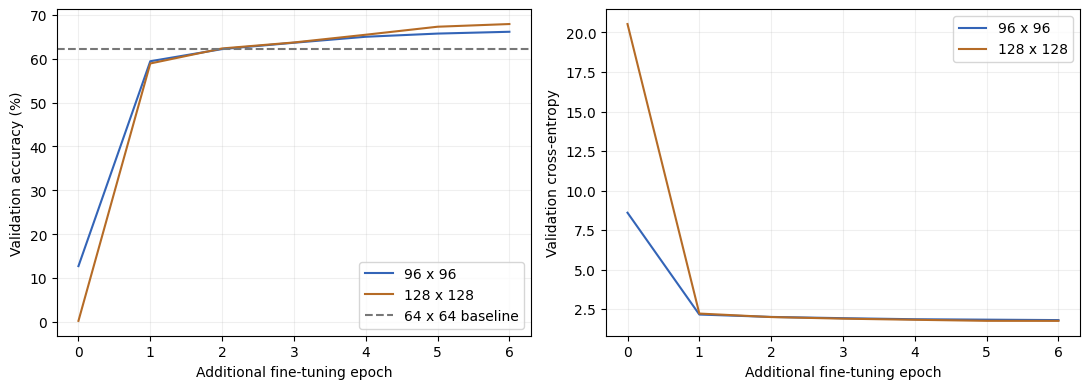

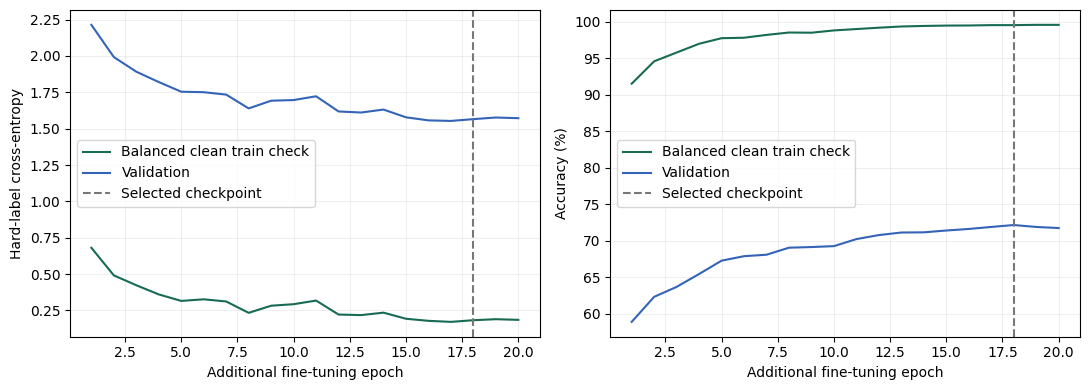

In [15]:
if RUN_MODE == "study":
    figure, axes = plt.subplots(1, 2, figsize=(11, 4))
    for pilot, color in zip(study_result["pilots"], ("#3364b7", "#b56b26")):
        history = json.loads((Path(pilot["directory"]) / "history.json").read_text())
        history = [entry for entry in history if entry["epoch"] <= PILOT_EPOCHS]
        epochs = [0] + [entry["epoch"] for entry in history]
        accuracy = [pilot["initial_validation"]["accuracy"]] + [entry["validation"]["accuracy"] for entry in history]
        losses = [pilot["initial_validation"]["loss"]] + [entry["validation"]["loss"] for entry in history]
        axes[0].plot(epochs, np.array(accuracy) * 100, color=color, label=f"{pilot['input_size']} x {pilot['input_size']}")
        axes[1].plot(epochs, losses, color=color, label=f"{pilot['input_size']} x {pilot['input_size']}")
    axes[0].axhline(100 * baseline_validation["accuracy"], linestyle="--", color="#777777", label="64 x 64 baseline")
    axes[0].set_ylabel("Validation accuracy (%)")
    axes[1].set_ylabel("Validation cross-entropy")
    for axis in axes:
        axis.set_xlabel("Additional fine-tuning epoch")
        axis.grid(alpha=0.2)
        axis.legend()
    figure.tight_layout()
    figure.savefig(STUDY_ROOT / "pilot_comparison.png", dpi=180, bbox_inches="tight")
    plt.show()
    
    selected_history = json.loads((Path(study_result["selected"]["directory"]) / "history.json").read_text())
    epochs = [entry["epoch"] for entry in selected_history]
    figure, axes = plt.subplots(1, 2, figsize=(11, 4))
    for split, label, color in (
        ("train_check", "Balanced clean train check", "#176b53"),
        ("validation", "Validation", "#3364b7"),
    ):
        axes[0].plot(epochs, [entry[split]["loss"] for entry in selected_history], label=label, color=color)
        axes[1].plot(epochs, [100 * entry[split]["accuracy"] for entry in selected_history], label=label, color=color)
    axes[0].set_ylabel("Hard-label cross-entropy")
    axes[1].set_ylabel("Accuracy (%)")
    for axis in axes:
        axis.set_xlabel("Additional fine-tuning epoch")
        axis.axvline(study_result["selected"]["best_epoch"], color="#777777", linestyle="--", label="Selected checkpoint")
        axis.grid(alpha=0.2)
        axis.legend()
    figure.tight_layout()
    figure.savefig(STUDY_ROOT / "selected_learning_curves.png", dpi=180, bbox_inches="tight")
    plt.show()

In [16]:
if RUN_MODE == "study":
    display(Markdown(
        f"The selected model reaches **{100 * study_result['train_check']['accuracy']:.3f}%** "
        f"on the balanced 8,000-image clean training check and "
        f"**{100 * study_result['validation']['accuracy']:.3f}%** on validation. "
        f"The train–validation gap is **{study_result['train_validation_gap_percentage_points']:.3f} percentage points**, "
        f"compared with **{study_result['baseline_gap_percentage_points']:.3f}** for the baseline. "
        f"Mean confidence on incorrect validation predictions changes from "
        f"{baseline_validation['confidence_wrong']:.3f} to "
        f"{study_result['validation']['confidence_wrong']:.3f}. "
        "Substantial overfitting remains despite the improvement. "
        "The 128 x 128 input upsamples the original 64 x 64 images and adds no new image detail. "
        "This result describes the measured candidates and validation protocol; it is not a global optimum. "
        "The later verification experiment will measure cosine/Euclidean ROC/AUC."
    ))

The selected model reaches **99.513%** on the balanced 8,000-image clean training check and **72.162%** on validation. The train–validation gap is **27.350 percentage points**, compared with **37.663** for the baseline. Mean confidence on incorrect validation predictions changes from 0.613 to 0.232. Substantial overfitting remains despite the improvement. The 128 x 128 input upsamples the original 64 x 64 images and adds no new image detail. This result describes the measured candidates and validation protocol; it is not a global optimum. The later verification experiment will measure cosine/Euclidean ROC/AUC.

## Restore the selected 512-dimensional model

In [17]:
if RUN_MODE == "study":
    selected_model, selected_checkpoint = load_selected_model(study_result["selected"])
    raw_sample, label_sample = next(raw_batches("validation", 8))
    with torch.inference_mode():
        sample_logits, sample_embeddings = selected_model(
            make_inputs(raw_sample, selected_checkpoint["input_size"][0])
        )
    assert sample_embeddings.shape == (8, 512)
    assert torch.isfinite(sample_embeddings).all()
    assert torch.allclose(
        sample_embeddings.norm(dim=1), torch.ones(8, device="cuda"), atol=1e-5
    )
    print("Embedding shape", tuple(sample_embeddings.shape))
    print("Embedding norms", sample_embeddings.norm(dim=1).cpu().tolist())
    print("Checkpoint SHA-256", study_result["selected"]["checkpoint_sha256"])
    print("Stored preprocessing", selected_checkpoint["input_size"], selected_checkpoint["normalization"])
    del selected_model, selected_checkpoint, sample_logits, sample_embeddings, raw_sample, label_sample
    torch.cuda.empty_cache()

Embedding shape (8, 512)
Embedding norms [1.0, 1.0, 1.0, 1.0, 0.9999999403953552, 1.0, 1.0, 1.0]
Checkpoint SHA-256 f21986bb5881d5a190daabea76a86173c8577bfe3a7ae7b3e99164eea8729896
Stored preprocessing [128, 128] {'mean': [0.485, 0.456, 0.406], 'std': [0.229, 0.224, 0.225]}


## References and reproducibility

- [Selected Kaggle dataset](https://www.kaggle.com/datasets/tranphamthanhtruc/project-dataset)
- [CMU classification/verification specification](https://deeplearning.cs.cmu.edu/F20/document/homework/Homework_2_2.pdf)
- [Torchvision ResNet-18 and ImageNet initialization](https://docs.pytorch.org/vision/0.21/models/generated/torchvision.models.resnet18.html)
- [Torchvision MixUp guidance](https://docs.pytorch.org/vision/0.21/auto_examples/transforms/plot_cutmix_mixup.html)
- [Label smoothing in Rethinking the Inception Architecture](https://arxiv.org/abs/1512.00567)
- [PyTorch mixed precision](https://docs.pytorch.org/docs/2.6/notes/amp_examples.html)

Run configuration, manifests, array hashes, baseline fingerprint, epoch histories, pilot selection and final checkpoint fingerprints are stored under the study directory. Checkpoints and data remain in git-ignored storage. Every project-specific implementation used by this notebook is present in the cells above.
- [Google Colab resource limits, notebook uploads and Drive I/O guidance](https://research.google.com/colaboratory/faq.html)
